# 08 — Control networks and the final comparison

Notebook 07 asked whether the fly reservoir beats the baselines. This notebook asks the harder question: **does the fly's specific wiring matter, or would any reservoir of the same size do as well?** Each control removes one thing about the fly. All four networks are tuned and scored identically (same 40 configurations, same input matrix `W_in`, same readout units, same folds). **The locked 2021–2025 test set is never scored.**

| Network | Keeps | Destroys | Question it answers |
|---|---|---|---|
| **fly** | everything | nothing | the real wiring |
| **weight-shuffled** | exact wiring, per-neuron signs | which synapse is strong or weak | do synapse *strengths* matter, or only topology? |
| **degree-preserving rewired** | every neuron's in- and out-degree, per-neuron signs | who connects to whom | does *specific* wiring matter beyond the hubs? |
| **random (Erdős–Rényi)** | neuron count, connection count, weight distribution, share of inhibitory connections | all structure | does *any* structure matter? |

The 285 input neurons keep their identity in every control, so the same features drive the same neuron indices.

### What is reported
1. Tuned leaderboard for all networks against the naive baseline and ridge.
2. **Multiple seeds:** the best configuration of each network is re-run with 5 different `W_in` draws (and, for controls, 5 different random graphs) to get a mean and spread. A difference between networks smaller than this spread is not a finding.
3. **Paired country-cluster bootstrap** of every comparison that matters (fly vs ridge, fly vs each control).
4. Where the gains come from (row type) and onset detection.

`QUICK_TEST = True` runs 2 configurations at horizon 1 with 1 extra seed. Progress is saved to `results/reservoir_log.csv`, so an interrupted run resumes. Notebook 06 must have been run first (it saves the baseline predictions used in the paired comparison).

## Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score

from src.paths import ROOT
from src.eval.splits import FOLDS
from src.eval.paired import cluster_bootstrap_rmse_diff
from src.models.common import HORIZONS as ALL_H, KINDS
from src.models.readout import LAMBDAS
from src.models.reservoir_search import ReservoirLab, sample_configs, tune, best_configs
from src.networks.controls import KINDS as NETS

# ------------------------------------------------------------------ settings
QUICK_TEST = False
N_ITER = 40
SEED = 42
N_READOUT = 1024
N_SEEDS = 5              # extra seeds for the best configuration of each network
N_BOOT = 2000
HORIZONS = [1] if QUICK_TEST else ALL_H
if QUICK_TEST:
    N_ITER, N_SEEDS, N_BOOT = 2, 1, 300
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
LOG = RESULTS / ("reservoir_log_quicktest.csv" if QUICK_TEST else "reservoir_log.csv")
BASE = RESULTS / ("baseline_predictions_quicktest.parquet" if QUICK_TEST else "baseline_predictions.parquet")
pd.set_option("display.width", 160, "display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

NET_NAMES = {"fly": "fly", "shuffled": "weight-shuffled", "rewired": "degree-preserving rewired", "er": "random (Erdős–Rényi)"}
COLORS = {"naive (best window)": "#8a8a85", "ridge": "#2a78d6", "fly": "#1baf7a", "weight-shuffled": "#eb6834",
          "degree-preserving rewired": "#9b59b6", "random (Erdős–Rényi)": "#c9a227"}
print(f"QUICK_TEST={QUICK_TEST}  horizons={HORIZONS}  N_ITER={N_ITER}  seeds={N_SEEDS}")

QUICK_TEST=False  horizons=[1, 3, 6, 12]  N_ITER=40  seeds=5


## 1. Build the control networks and check they do what they claim
Every control is checked against the fly: same number of neurons and connections, and the property it is meant to preserve (or break) is verified, not assumed.

In [2]:
lab = ReservoirLab(horizons=HORIZONS, n_random=N_READOUT, seed=SEED)
A = lab.A
deg = lambda M: (np.diff(M.tocsr().indptr), np.diff(M.tocsc().indptr))
fly_edges = set(zip(*A.nonzero()))
rows = []
for kind in NETS:
    t = time.time(); B, rho0 = lab.network(kind, 0)
    out_ok, in_ok = (deg(B)[0] == deg(A)[0]).all(), (deg(B)[1] == deg(A)[1]).all()
    overlap = len(fly_edges & set(zip(*B.nonzero()))) / A.nnz
    rows.append({"network": NET_NAMES[kind], "connections": B.nnz, "inhibitory share": float(np.mean(B.data < 0)),
                 "same out-degrees": out_ok, "same in-degrees": in_ok, "connections shared with fly": overlap,
                 "spectral radius (raw)": rho0, "build s": round(time.time() - t, 1)})
ctl = pd.DataFrame(rows).set_index("network"); display(ctl.round(3))
assert ctl.loc["degree-preserving rewired", ["same out-degrees", "same in-degrees"]].all()
assert ctl.loc["weight-shuffled", "connections shared with fly"] == 1.0
assert (ctl["connections"] == ctl.loc["fly", "connections"]).all()

,connections,inhibitory share,same out-degrees,same in-degrees,connections shared with fly,spectral radius (raw),build s
network,,,,,,,
fly,92642,0.07,True,True,1.000,1.000,0.1
weight-shuffled,92642,0.07,True,True,1.000,3.200,0.1
degree-preserving rewired,92642,0.07,True,True,0.104,3.873,1.8
random (Erdős–Rényi),92642,0.07,False,False,0.003,0.491,0.1


Expected: **weight-shuffled** shares every connection with the fly; **rewired** keeps every in- and out-degree but shares few connections; **random** keeps only the counts. All are rescaled to the same spectral radius `rho` inside the search, so the raw radius above does not matter.

## 2. Tune the controls (same configurations as the fly)

In [3]:
CONFIGS = sample_configs(N_ITER, SEED)
for kind in NETS:
    tune(lab, kind, CONFIGS, LOG)      # the fly is skipped if notebook 07 already logged it
log = pd.read_csv(LOG)
print("networks in log:", sorted(log["network"].unique()))

[shuffled] config 1/40 done  (0.4 min elapsed)
[shuffled] config 2/40 done  (0.7 min elapsed)
[shuffled] config 3/40 done  (1.0 min elapsed)
[shuffled] config 4/40 done  (1.4 min elapsed)
[shuffled] config 5/40 done  (1.7 min elapsed)
[shuffled] config 6/40 done  (2.0 min elapsed)
[shuffled] config 7/40 done  (2.4 min elapsed)
[shuffled] config 8/40 done  (2.7 min elapsed)
[shuffled] config 9/40 done  (3.1 min elapsed)
[shuffled] config 10/40 done  (3.4 min elapsed)
[shuffled] config 11/40 done  (3.7 min elapsed)
[shuffled] config 12/40 done  (4.1 min elapsed)
[shuffled] config 13/40 done  (4.4 min elapsed)
[shuffled] config 14/40 done  (4.7 min elapsed)
[shuffled] config 15/40 done  (5.0 min elapsed)
[shuffled] config 16/40 done  (5.4 min elapsed)
[shuffled] config 17/40 done  (5.7 min elapsed)
[shuffled] config 18/40 done  (6.0 min elapsed)
[shuffled] config 19/40 done  (6.4 min elapsed)
[shuffled] config 20/40 done  (6.8 min elapsed)
[shuffled] config 21/40 done  (7.1 min elapsed)
[

## 3. Leaderboard (best configuration per network and horizon, folds 1–5)

In [4]:
best = best_configs(log)
lb = pd.read_csv(RESULTS / ("leaderboard_quicktest.csv" if QUICK_TEST else "leaderboard.csv"))
tab = lb.pivot(index="horizon", columns="model", values="rmse")[["naive (best window)", "ridge", "random forest", "gradient boosting"]]
for kind in NETS:
    tab[NET_NAMES[kind]] = best[(best["network"] == kind) & (best["variant"] == "random")].set_index("horizon")["rmse"]
tab = tab.loc[HORIZONS]
display(tab.round(4))
print("Skill vs ridge (1 - RMSE / RMSE ridge; positive = better than ridge):")
display((1 - tab.div(tab["ridge"], axis=0))[[NET_NAMES[k] for k in NETS]].round(4))
print("MBON-only readout (96 units) vs 1,024 random units, same network:")
mb = best[best["network"] == "fly"].pivot(index="horizon", columns="variant", values="rmse")[["random", "mbon"]]
display(mb.rename(columns={"random": "1,024 random units", "mbon": "96 MBONs"}).round(4))

model,naive (best window),ridge,random forest,gradient boosting,fly,weight-shuffled,degree-preserving rewired,random (Erdős–Rényi)
horizon,,,,,,,,
1,0.5282,0.5033,0.5048,0.5073,0.5026,0.5027,0.5019,0.5025
3,0.5892,0.5707,0.5783,0.5824,0.5702,0.5700,0.5704,0.5692
6,0.6320,0.6216,0.6322,0.6354,0.6206,0.6208,0.6209,0.6197
12,0.7093,0.6887,0.7012,0.7101,0.6877,0.6879,0.6880,0.6870


Skill vs ridge (1 - RMSE / RMSE ridge; positive = better than ridge):


model,fly,weight-shuffled,degree-preserving rewired,random (Erdős–Rényi)
horizon,,,,
1,0.0014,0.0011,0.0027,0.0017
3,0.0009,0.0012,0.0005,0.0027
6,0.0016,0.0013,0.0011,0.0030
12,0.0015,0.0012,0.0010,0.0024


MBON-only readout (96 units) vs 1,024 random units, same network:


variant,"1,024 random units",96 MBONs
horizon,,
1,0.5026,0.5025
3,0.5702,0.5698
6,0.6206,0.6202
12,0.6877,0.6874


## 4. Seeds: how much of any difference is just randomness?
For each network and horizon, the best configuration (and ridge penalty) is re-run with new random input matrices `W_in` and, for controls, new random graphs. This is the spread to compare differences against.

In [5]:
SEED_RESULTS = RESULTS / ("reservoir_seeds_quicktest.csv" if QUICK_TEST else "reservoir_seeds.csv")
if SEED_RESULTS.exists():
    seeds = pd.read_csv(SEED_RESULTS)
else:
    rows = []
    for kind in NETS:
        for h in HORIZONS:
            b = best[(best["network"] == kind) & (best["variant"] == "random") & (best["horizon"] == h)].iloc[0]
            cfg = json.loads(b["params"]); lam = int(b["lambda_id"])
            for s in range(0, N_SEEDS + 1):               # seed 0 = the tuned run
                res = lab.evaluate(kind, cfg, w_seed=s, graph_seed=s, variants=("random",), horizons=[h])
                rm = res[("random", h)][0]
                rows.append({"network": NET_NAMES[kind], "horizon": h, "seed": s, "rmse": rm[:, lam].mean()})
            print(f"{NET_NAMES[kind]:<28} horizon {h:>2} done", flush=True)
    seeds = pd.DataFrame(rows); seeds.to_csv(SEED_RESULTS, index=False)
extra = seeds[seeds["seed"] > 0]
sm = extra.groupby(["horizon", "network"])["rmse"].agg(["mean", "std"]).unstack("network")
display(sm["mean"].round(4)); print("standard deviation across seeds:"); display(sm["std"].round(4))

fly                          horizon  1 done
fly                          horizon  3 done
fly                          horizon  6 done
fly                          horizon 12 done
weight-shuffled              horizon  1 done
weight-shuffled              horizon  3 done
weight-shuffled              horizon  6 done
weight-shuffled              horizon 12 done
degree-preserving rewired    horizon  1 done
degree-preserving rewired    horizon  3 done
degree-preserving rewired    horizon  6 done
degree-preserving rewired    horizon 12 done
random (Erdős–Rényi)         horizon  1 done
random (Erdős–Rényi)         horizon  3 done
random (Erdős–Rényi)         horizon  6 done
random (Erdős–Rényi)         horizon 12 done


network,degree-preserving rewired,fly,random (Erdős–Rényi),weight-shuffled
horizon,,,,
1,0.5021,0.5028,0.5032,0.5028
3,0.5710,0.5704,0.5712,0.5703
6,0.6208,0.6209,0.6221,0.6208
12,0.6880,0.6880,0.6889,0.6879


standard deviation across seeds:


network,degree-preserving rewired,fly,random (Erdős–Rényi),weight-shuffled
horizon,,,,
1,0.0008,0.0000,0.0003,0.0001
3,0.0006,0.0001,0.0005,0.0005
6,0.0001,0.0002,0.0008,0.0002
12,0.0002,0.0003,0.0014,0.0003


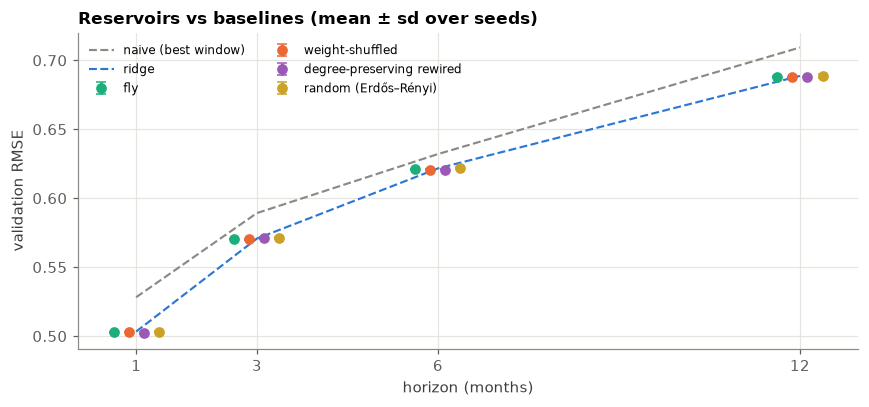

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [NET_NAMES[k] for k in NETS]
for i, n in enumerate(names):
    s = extra[extra["network"] == n].groupby("horizon")["rmse"].agg(["mean", "std"]).reindex(HORIZONS)
    ax.errorbar(np.array(HORIZONS) + (i - 1.5) * 0.25, s["mean"], yerr=s["std"].fillna(0), fmt="o", capsize=3, color=COLORS[n], label=n)
for m in ["naive (best window)", "ridge"]:
    ax.plot(HORIZONS, tab[m], color=COLORS[m], ls="--", lw=1.4, label=m)
ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (months)"); ax.set_ylabel("validation RMSE")
ax.set_title("Reservoirs vs baselines (mean ± sd over seeds)"); ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## 5. Paired comparison with country-cluster bootstrap
Predictions of each network's best configuration (seed 0) on the validation rows are compared on the same rows with the same bootstrap as notebook 06. **RMSE(A) − RMSE(B); negative = A better.**

In [7]:
base = pd.read_parquet(BASE)
KEEP = ["gwno", "country", "month", "y", "kind", "at_risk", "event"]
RP = []
for kind in NETS:
    for h in HORIZONS:
        b = best[(best["network"] == kind) & (best["variant"] == "random") & (best["horizon"] == h)].iloc[0]
        cfg = json.loads(b["params"]); lam = int(b["lambda_id"])
        res = lab.evaluate(kind, cfg, w_seed=0, graph_seed=0, variants=("random",), horizons=[h], predictions=True)
        P = res[("random", h)][2]; d = lab.tables[h]
        for f, va, p in zip(FOLDS, lab.masks[h][1], P):
            RP.append(d.loc[va, KEEP].assign(horizon=h, model=NET_NAMES[kind], fold=f.name, pred=p[:, lam]))
RP = pd.concat(RP, ignore_index=True)
ALLP = pd.concat([base, RP], ignore_index=True)
RP.to_parquet(RESULTS / ("reservoir_predictions_quicktest.parquet" if QUICK_TEST else "reservoir_predictions.parquet"))
print(len(ALLP), "prediction rows")

979504 prediction rows


In [8]:
pairs = [("fly", "ridge"), ("fly", "naive (best window)"), ("fly", "weight-shuffled"),
         ("fly", "degree-preserving rewired"), ("fly", "random (Erdős–Rényi)"), ("ridge", "naive (best window)")]
rows = []
for h in HORIZONS:
    wide = ALLP[ALLP["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    yy = ALLP[(ALLP["horizon"] == h) & (ALLP["model"] == "ridge")].set_index(["gwno", "month"])["y"]
    wide = wide.join(yy).reset_index().dropna()
    for a, b in pairs:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b], wide["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b, **r})
paired = pd.DataFrame(rows); paired["significant"] = (paired["lo"] > 0) | (paired["hi"] < 0)
display(paired.round(4))
paired.round(5).to_csv(RESULTS / ("paired_reservoir_quicktest.csv" if QUICK_TEST else "paired_reservoir.csv"), index=False)

,horizon,A,B,diff,lo,hi,p_a_better,significant
0,1,fly,ridge,-0.0007,-0.0014,0.0001,0.9570,False
1,1,fly,naive (best window),-0.0257,-0.0348,-0.0157,1.0000,True
2,1,fly,weight-shuffled,-0.0001,-0.0002,-0.0000,0.9930,True
3,1,fly,degree-preserving rewired,0.0007,-0.0016,0.0030,0.2820,False
4,1,fly,random (Erdős–Rényi),0.0001,-0.0010,0.0012,0.4090,False
5,1,ridge,naive (best window),-0.0250,-0.0340,-0.0153,1.0000,True
6,3,fly,ridge,-0.0005,-0.0020,0.0010,0.7590,False
7,3,fly,naive (best window),-0.0190,-0.0319,-0.0058,0.9985,True
8,3,fly,weight-shuffled,0.0001,-0.0010,0.0013,0.4420,False
9,3,fly,degree-preserving rewired,-0.0003,-0.0018,0.0013,0.6700,False


## 6. Where does any gain come from? Row type and onset detection

In [9]:
show = ["naive (best window)", "ridge"] + [NET_NAMES[k] for k in NETS]
rows = []
for (h, m), p in ALLP[ALLP["model"].isin(show)].groupby(["horizon", "model"]):
    r = {"horizon": h, "model": m, "all rows": np.sqrt(np.mean((p["y"] - p["pred"]) ** 2))}
    for k in KINDS:
        s = p[p["kind"] == k]; r[k] = np.sqrt(np.mean((s["y"] - s["pred"]) ** 2))
    a = p[p["at_risk"]]; r["onset AP"] = average_precision_score(a["event"], a["pred"])
    rows.append(r)
bykind = pd.DataFrame(rows)
for h in HORIZONS:
    print(f"Horizon {h}: RMSE by row type, and onset average precision (pooled folds 1-5)")
    display(bykind[bykind["horizon"] == h].drop(columns="horizon").set_index("model").reindex(show).round(3))
bykind.round(4).to_csv(RESULTS / ("reservoir_by_kind_quicktest.csv" if QUICK_TEST else "reservoir_by_kind.csv"), index=False)

Horizon 1: RMSE by row type, and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
naive (best window),0.529,0.159,1.788,1.022,1.589,0.095
ridge,0.504,0.114,1.815,0.953,1.584,0.106
fly,0.503,0.114,1.813,0.953,1.577,0.106
weight-shuffled,0.503,0.114,1.813,0.953,1.578,0.107
degree-preserving rewired,0.503,0.118,1.797,0.958,1.558,0.102
random (Erdős–Rényi),0.503,0.115,1.808,0.954,1.575,0.106


Horizon 3: RMSE by row type, and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
naive (best window),0.589,0.171,1.941,1.126,1.700,0.100
ridge,0.571,0.142,1.958,1.084,1.649,0.103
fly,0.570,0.142,1.956,1.084,1.645,0.108
weight-shuffled,0.570,0.141,1.960,1.082,1.650,0.109
degree-preserving rewired,0.571,0.140,1.958,1.084,1.652,0.106
random (Erdős–Rényi),0.569,0.143,1.949,1.079,1.653,0.108


Horizon 6: RMSE by row type, and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
naive (best window),0.632,0.179,2.049,1.206,1.775,0.117
ridge,0.622,0.161,2.062,1.199,1.693,0.115
fly,0.621,0.161,2.058,1.197,1.689,0.122
weight-shuffled,0.621,0.162,2.054,1.201,1.682,0.119
degree-preserving rewired,0.621,0.162,2.054,1.201,1.683,0.119
random (Erdős–Rényi),0.620,0.165,2.047,1.191,1.703,0.124


Horizon 12: RMSE by row type, and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
naive (best window),0.710,0.168,2.321,1.298,1.996,0.131
ridge,0.690,0.177,2.239,1.318,1.753,0.149
fly,0.689,0.177,2.235,1.316,1.751,0.150
weight-shuffled,0.689,0.177,2.236,1.317,1.751,0.149
degree-preserving rewired,0.689,0.177,2.234,1.317,1.751,0.149
random (Erdős–Rényi),0.688,0.181,2.234,1.304,1.771,0.152


## 7. Reading the results
Fill in after the full run. Decide in this order:

1. **Does the fly beat ridge?** Use the paired interval (section 5), not the leaderboard difference. If the interval spans 0, the reservoir adds nothing measurable over ridge on the raw features.
2. **Does the fly beat the controls?** Only a fly-vs-control interval that excludes 0, *and* a gap larger than the seed spread (section 4), supports "the wiring matters". If the controls tie the fly, the honest conclusion is that a reservoir of this size and density does the work, whatever its wiring.
3. **Which control matters?** Fly vs shuffled isolates synapse strengths; fly vs rewired isolates specific connections beyond the degree pattern; fly vs random isolates structure of any kind.
4. **Where is the gain?** Row-type and onset tables show whether a gain is on the quiet majority or on the hard onset and continuation rows.
5. **Report everything,** including a null result. A well-controlled null (reservoir ≈ ridge ≈ controls) is a legitimate finding.

Remaining robustness checks from the project guide (APL ablation, glutamate sign, weight schemes, hemisphere replication, a larger readout, multiple graph seeds for the fly's input matrix) are cheap extensions of `ReservoirLab` and are left for after these results are reviewed.